# Data Collection, Cleaning, and Exploration
## Factors Associated with Five-Year Home Price Growth in California

**Name:** Sammy Sheu
**Course:** MSCS 634 — Big Data and Data Mining

---

### The question

> Given what a California ZIP code looked like at the end of a given year, what happened to its home
> prices over the **following five years** — and which market, economic and demographic factors are
> associated with that growth?

### The dataset

One row = **one California ZIP code observed in one base year**. Five base years (2016–2020) are
stacked into a single panel, so the same ZIP code appears once per base year.

| zip_code | base_year | current_home_value | … | future_5yr_growth_pct |
|---|---|---|---|---|
| 94533 | 2016 | 310,000 | … | 41.2 |
| 94533 | 2020 | 402,000 | … | 38.6 |

Because every outcome window (2021–2025) has **already fully elapsed**, the target is a **measured
outcome, not a forecast**. Predictions can be checked against what actually happened.

### Why this dataset is appropriate

**Size.** 7,487 records × 12 core features — comfortably above the 500-record, 8–10 attribute
requirement.

**Real-world relevance.** Housing affordability is a live California policy problem. Buyers,
planners and lenders genuinely want to know which markets are about to appreciate.

**Genuine analytical difficulty — this is not a toy dataset.**

| Difficulty | Where it appears |
|---|---|
| Authentic missing data | Rent index is 78% missing, and the missingness is **not random** |
| Authentic outliers | Atherton at a $6.5M typical home value is not a typo; it is Atherton |
| Structural absence vs. missingness | Listings data does not exist before 2018 — a different problem from "missing" |
| A leakage trap | The five outcome windows overlap, so rows are not fully independent |
| A confounded feature | The mortgage rate is national — one value per year |

### Sources

| Source | Contributes |
|---|---|
| **Zillow ZHVI** (ZIP, smoothed, seasonally adjusted) | Home values: level, momentum, and the five-year outcome |
| **Zillow ZORI** (ZIP) | Observed asking rent — sparse; used as a supplementary column |
| **Zillow listings** (inventory, new listings, price cuts, median list price) | Market liquidity, 2018-03 onward |
| **US Census ACS 5-Year** (ZCTA) | Income, rent, population, housing units, unemployment, education |
| **FRED `MORTGAGE30US`** | National 30-year fixed mortgage rate |

### The target

```python
future_5yr_growth_pct = (future_5yr_home_value / current_home_value - 1) * 100
```

**Why predict growth rather than the future price.** If the target were the future *price*,
`current_home_value` would dominate everything — a $1M home is still expensive five years later. A
model would post a high R² while explaining nothing. Predicting **growth** forces the features to
explain *why* prices move. The dollar figure is recovered afterwards by multiplying back out.

`future_5yr_home_value` is therefore kept for reference only and **must be excluded from any feature
matrix** — it is the target restated, and using it would be direct leakage.

---
## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

# --- Plot theme ---------------------------------------------------------------------------------
# Colour is assigned by the job it does, not by taste:
#   ORDINAL (base year 2016 -> 2020): one blue hue, light -> dark, so the years read as ordered
#       rather than as five unrelated categories.
#   CATEGORICAL (a few named ZIP codes): a fixed hue order, never cycled.
#   DIVERGING (correlation heatmap): blue <-> red with a NEUTRAL GRAY midpoint, so "no correlation"
#       reads as nothing. A rainbow map would invent structure that isn't in the data.
YEAR_COLORS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]   # ordinal, 2016 -> 2020
CATEGORICAL = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7"]
BLUE, ACCENT, GRAY = "#2a78d6", "#eb6834", "#52514e"
DIVERGING = LinearSegmentedColormap.from_list(
    "blue_gray_red",
    ["#104281", "#2a78d6", "#86b6ef", "#f0efec", "#f0a09f", "#e34948", "#a32423"],
)

mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,   # recessive frame
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": "#0b0b0b",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e7e6e2", "grid.linewidth": 0.8,   # recessive grid
    "axes.axisbelow": True,
    "text.color": "#0b0b0b", "xtick.color": GRAY, "ytick.color": GRAY,
    "font.size": 10, "figure.dpi": 110, "savefig.bbox": "tight",
    "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=150)

BASE_YEARS = [2016, 2017, 2018, 2019, 2020]
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.3 | numpy 2.5.1


---
## 1. Loading the data and assembling the panel

### How each row is built

December is the anchor month: Zillow publishes monthly, and December is an unambiguous year-end that
avoids depending on the most recent, still-revising month.

For each base year *t*:

| Block | Anchors |
|---|---|
| Home values | ZHVI at Dec(t−3), Dec(t−1), Dec(t), Dec(t+5) → level, 1-yr and 3-yr momentum, and the target |
| Demographics | ACS 5-Year at *t* and *t−5* → income, rent, population growth, unemployment, education, housing units |
| Macro | FRED annual mean of the weekly 30-year rate for year *t* |
| Derived | `price_to_income_ratio`, `price_to_rent_ratio` |
| Listings | attached for t ∈ {2018, 2019, 2020}; **not available for 2016–2017** |

A row exists only if ZHVI is present at Dec(t−1), Dec(t) **and** Dec(t+5) — that is, only if both the
starting value and the realized outcome can actually be computed.

### Two loading decisions that are easy to get wrong

1. **ZIP codes are read as strings, not integers.** Read as an int, `"01234"` silently becomes `1234`.
   Leading zeros do not occur in California, but the habit is the correct one and costs nothing.
2. **Zillow ships in *wide* format** — one column per month, 300+ of them. We select **only the four
   anchor months** we need per base year. Melting all 300+ columns would generate millions of rows we
   would immediately discard.

In [2]:
# ---- Source files -------------------------------------------------------------------------------
ZHVI_PATH = RAW / "Zip_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv"
ZORI_PATH = RAW / "Zip_zori_uc_sfrcondomfr_sm_month.csv"
FRED_PATH = RAW / "MORTGAGE30US.csv"
LISTINGS_FILES = {
    "for_sale_inventory": "Zip_invt_fs_uc_sfrcondo_sm_month.csv",
    "new_listings":       "Zip_new_listings_uc_sfrcondo_sm_month.csv",
    "price_cut_pct":      "Zip_perc_listings_price_cut_uc_sfrcondo_sm_month.csv",
    "median_list_price":  "Zip_mlp_uc_sfrcondo_sm_month.csv",
}
# Every listings series begins 2018-03. For 2016-2017 these columns are STRUCTURALLY ABSENT.
LISTINGS_START_YEAR = 2018


def load_zillow_ca(path):
    """Load a wide Zillow file, keep California, index by 5-digit ZIP string."""
    df = pd.read_csv(path, dtype={"RegionName": str})     # dtype=str preserves leading zeros
    df = df[df["State"] == "CA"].copy()
    df["RegionName"] = df["RegionName"].str.zfill(5)
    return df.set_index("RegionName")


def load_acs(year):
    """One ACS 5-Year vintage, by ZIP Code Tabulation Area."""
    return pd.read_csv(RAW / "acs" / f"acs5_{year}.csv", dtype={"zip_code": str}).set_index("zip_code")


zhvi = load_zillow_ca(ZHVI_PATH)
zori = load_zillow_ca(ZORI_PATH)
listings = {name: load_zillow_ca(RAW / f) for name, f in LISTINGS_FILES.items()}

# The mortgage rate is published weekly and nationally; collapse it to an annual mean.
fred = pd.read_csv(FRED_PATH, parse_dates=["observation_date"])
mortgage_by_year = fred.groupby(fred["observation_date"].dt.year)["MORTGAGE30US"].mean()

print(f"ZHVI: {len(zhvi):,} CA ZIP codes, {zhvi.shape[1]} columns (wide monthly format)")
print(f"ZORI: {len(zori):,} CA ZIP codes")
print(f"mortgage rate, annual mean:\n{mortgage_by_year.loc[2016:2020].round(2).to_string()}")

ZHVI: 1,543 CA ZIP codes, 325 columns (wide monthly format)
ZORI: 953 CA ZIP codes
mortgage rate, annual mean:
observation_date
2016   3.65
2017   3.99
2018   4.54
2019   3.94
2020   3.11


In [3]:
def dec(year):
    return f"{year}-12-31"


def build_base_year(year):
    """Assemble every California ZIP code for a single base year."""
    t, prev, t3, future = dec(year), dec(year - 1), dec(year - 3), dec(year + 5)

    # A row only exists if we can compute BOTH the starting value and the realized outcome.
    keep = zhvi[t].notna() & zhvi[prev].notna() & zhvi[future].notna()
    z = zhvi[keep]

    df = pd.DataFrame(index=z.index)
    df.index.name = "zip_code"
    df["base_year"] = year
    df["city"] = z["City"]
    df["county"] = z["CountyName"]

    # ---- Home values: level, momentum, and the target --------------------------------------------
    df["current_home_value"] = z[t]
    df["future_5yr_home_value"] = z[future]
    df["home_value_1yr_growth_pct"] = (z[t] / z[prev] - 1) * 100
    df["home_value_3yr_growth_pct"] = (z[t] / z[t3] - 1) * 100 if t3 in z.columns else np.nan
    df["future_5yr_growth_pct"] = (z[future] / z[t] - 1) * 100

    # ---- Observed rent index (supplementary; see the cleaning section) ---------------------------
    df["zori_rent"] = zori[t].reindex(df.index) if t in zori.columns else np.nan
    df["zori_rent_available"] = df["zori_rent"].notna().astype(int)

    # ---- Census ACS: levels at t, plus population at t-5 for a non-overlapping growth window -----
    acs, acs_lag = load_acs(year).reindex(df.index), load_acs(year - 5).reindex(df.index)

    df["median_household_income"] = acs["B19013_001E"]
    df["median_gross_rent"] = acs["B25064_001E"]
    df["population"] = acs["B01003_001E"]
    df["housing_units"] = acs["B25001_001E"]

    labor_force = acs["B23025_003E"].replace(0, np.nan)          # avoid divide-by-zero
    df["unemployment_rate"] = acs["B23025_005E"] / labor_force * 100

    adults = acs["B15003_001E"].replace(0, np.nan)               # population aged 25+
    bachelor_plus = acs[["B15003_022E", "B15003_023E", "B15003_024E", "B15003_025E"]].sum(
        axis=1, min_count=1)                                     # bachelor's + master's + prof + PhD
    df["bachelor_degree_pct"] = bachelor_plus / adults * 100

    pop_lag = acs_lag["B01003_001E"].replace(0, np.nan)
    df["population_growth_pct"] = (acs["B01003_001E"] / pop_lag - 1) * 100

    # ---- Macro: identical for every ZIP within a year --------------------------------------------
    df["mortgage_rate"] = mortgage_by_year.get(year, np.nan)

    # ---- Listings: 2018+ only. Raw COUNTS scale with ZIP size, so normalize by housing units,
    #      otherwise they merely proxy for how big the ZIP code is.
    per_1k = df["housing_units"].replace(0, np.nan) / 1000
    listing_cols = ["for_sale_inventory", "new_listings", "price_cut_pct", "median_list_price",
                    "inventory_per_1k_housing_units", "new_listings_per_1k_housing_units",
                    "list_to_value_ratio"]
    if year >= LISTINGS_START_YEAR:
        for name, lf in listings.items():
            df[name] = lf[t].reindex(df.index) if t in lf.columns else np.nan
        df["inventory_per_1k_housing_units"] = df["for_sale_inventory"] / per_1k
        df["new_listings_per_1k_housing_units"] = df["new_listings"] / per_1k
        df["list_to_value_ratio"] = df["median_list_price"] / df["current_home_value"]
    else:
        for name in listing_cols:
            df[name] = np.nan

    return df.reset_index()


raw = pd.concat([build_base_year(y) for y in BASE_YEARS], ignore_index=True)

print(f"raw panel: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print("\nrows per base year:")
print(raw["base_year"].value_counts().sort_index().to_string())

raw panel: 7,487 rows x 26 columns

rows per base year:
base_year
2016    1452
2017    1496
2018    1500
2019    1511
2020    1528


In [4]:
raw.head()

,zip_code,base_year,city,county,current_home_value,future_5yr_home_value,home_value_1yr_growth_pct,home_value_3yr_growth_pct,future_5yr_growth_pct,zori_rent,zori_rent_available,median_household_income,median_gross_rent,population,housing_units,unemployment_rate,bachelor_degree_pct,population_growth_pct,mortgage_rate,for_sale_inventory,new_listings,price_cut_pct,median_list_price,inventory_per_1k_housing_units,new_listings_per_1k_housing_units,list_to_value_ratio
0,90011,2016,Los Angeles,Los Angeles County,"292,266.88","554,428.39",9.89,30.87,89.70,NaN,0,"31,684.00","1,011.00","104,762.00","24,511.00",8.66,3.58,3.19,3.65,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,90650,2016,Norwalk,Los Angeles County,"395,687.20","659,410.79",6.30,17.63,66.65,NaN,0,"61,050.00","1,384.00","106,360.00","28,528.00",7.95,15.97,0.96,3.65,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,91331,2016,Los Angeles,Los Angeles County,"353,540.08","631,069.44",8.69,24.37,78.50,NaN,0,"53,714.00","1,315.00","101,536.00","23,277.00",11.79,10.36,4.11,3.65,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,90044,2016,Los Angeles,Los Angeles County,"320,546.12","614,314.22",8.87,28.78,91.65,NaN,0,"30,288.00",988.00,"90,155.00","29,458.00",11.73,7.37,2.26,3.65,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,92336,2016,Fontana,San Bernardino County,"387,365.95","623,872.15",4.09,17.92,61.05,NaN,0,"85,027.00","1,677.00","92,306.00","23,909.00",9.48,23.22,4.10,3.65,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7487 entries, 0 to 7486
Data columns (total 26 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   zip_code                           7487 non-null   str    
 1   base_year                          7487 non-null   int64  
 2   city                               7347 non-null   str    
 3   county                             7487 non-null   str    
 4   current_home_value                 7487 non-null   float64
 5   future_5yr_home_value              7487 non-null   float64
 6   home_value_1yr_growth_pct          7487 non-null   float64
 7   home_value_3yr_growth_pct          7326 non-null   float64
 8   future_5yr_growth_pct              7487 non-null   float64
 9   zori_rent                          1660 non-null   float64
 10  zori_rent_available                7487 non-null   int64  
 11  median_household_income            7315 non-null   float64
 12  med

---
# 2. Data cleaning

This section comes **before** any exploration, deliberately: every statistic, correlation and box
plot in the EDA section is only as trustworthy as the table it is computed from. Each decision below
is stated together with **why** it was made — an imputation choice is an assumption about the world,
not a formality.

**Summary of the cleaning steps, in order:**

| # | Step | Action |
|---|---|---|
| 2.1 | Inspect missingness | Measure before deciding anything |
| 2.2 | Census null sentinels | Convert `-666666666` → `NaN` |
| 2.3 | Duplicate ZIP-year rows | Assert none exist; fail loudly |
| 2.4 | Impossible values | Out-of-range numbers → `NaN` |
| 2.5 | Missing target / denominator | **Drop the row** |
| 2.6 | Missing demographic features | **Median-impute within base year** |
| 2.7 | Severely / structurally missing columns | **Do not impute** |
| 2.8 | Outliers | **Flag, do not delete** |
| 2.9 | Verify | Confirm the result |

## 2.1 First, measure the missingness

You cannot choose a missing-value strategy before you know *which* columns are missing, *how much*,
and — most importantly — **why**. Different causes demand different responses, so the first step is
purely diagnostic.

In [6]:
missing_before = raw.isna().sum()
missing_summary = pd.DataFrame({
    "missing": missing_before,
    "pct": (missing_before / len(raw) * 100).round(1),
})
missing_summary[missing_summary["missing"] > 0].sort_values("missing", ascending=False)

,missing,pct
zori_rent,5827,77.80
new_listings,5753,76.80
new_listings_per_1k_housing_units,5753,76.80
list_to_value_ratio,5493,73.40
median_list_price,5493,73.40
price_cut_pct,5473,73.10
inventory_per_1k_housing_units,4084,54.50
for_sale_inventory,4081,54.50
median_gross_rent,409,5.50
median_household_income,172,2.30


### Figure A — Missing values by column

**Why plot this, and what I expect.** The table above is accurate but hard to *reason* about. I want
to see whether the missingness clusters into distinct groups, because my prior is that these columns
are not all missing for the same reason: I expect the **listings** columns to be missing in bulk
(their series starts in 2018), the **rent index** to be missing at a high but different rate, and the
**Census** columns to have only small scattered gaps. If that prior is right, then a single global
strategy — "impute everything with the median" — would be **exactly the wrong move**, and the chart
should make that obvious at a glance.

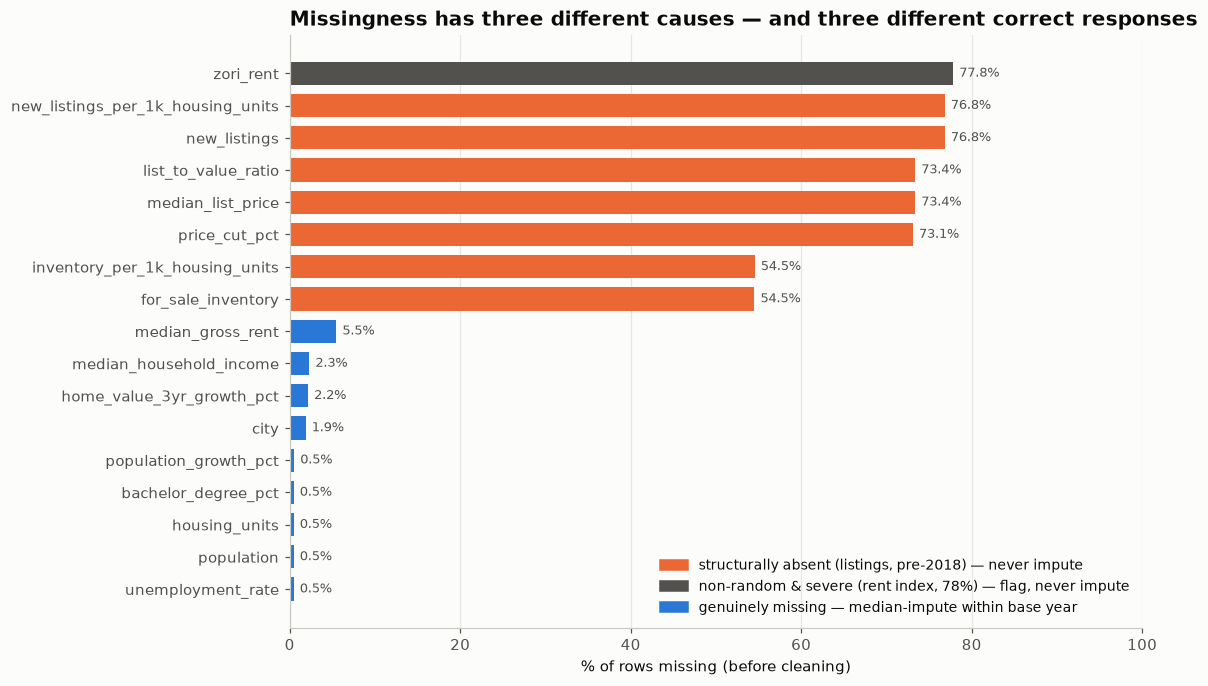

listings coverage within the 4,539 rows from 2018-2020, where the series exists:
  inventory_per_1k_housing_units        75.0% present
  new_listings_per_1k_housing_units     38.2% present
  price_cut_pct                         44.4% present
  list_to_value_ratio                   43.9% present


In [7]:
miss = (raw.isna().sum() / len(raw) * 100).sort_values()
miss = miss[miss > 0]

# Three colours, because these are three different problems with three different correct responses.
STRUCTURAL = {"for_sale_inventory", "new_listings", "price_cut_pct", "median_list_price",
              "inventory_per_1k_housing_units", "new_listings_per_1k_housing_units",
              "list_to_value_ratio"}
colors = [ACCENT if c in STRUCTURAL else (GRAY if c == "zori_rent" else BLUE) for c in miss.index]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(miss.index, miss.values, color=colors, height=0.72)
for i, v in enumerate(miss.values):
    ax.annotate(f"{v:.1f}%", (v, i), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=GRAY)
ax.set_xlim(0, 100)
ax.set_xlabel("% of rows missing (before cleaning)")
ax.set_title("Missingness has three different causes — and three different correct responses")
ax.grid(axis="y", visible=False)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in [ACCENT, GRAY, BLUE]]
ax.legend(handles, ["structurally absent (listings, pre-2018) — never impute",
                    "non-random & severe (rent index, 78%) — flag, never impute",
                    "genuinely missing — median-impute within base year"],
          loc="lower right", fontsize=9)
save(fig, "figA_missing_values")
plt.show()

# Coverage of the listings block WITHIN the years where the series exists at all.
sub = raw[raw["base_year"] >= LISTINGS_START_YEAR]
print(f"listings coverage within the {len(sub):,} rows from 2018-2020, where the series exists:")
for c in ["inventory_per_1k_housing_units", "new_listings_per_1k_housing_units",
          "price_cut_pct", "list_to_value_ratio"]:
    print(f"  {c:<36} {sub[c].notna().mean() * 100:5.1f}% present")

**Result — the prior was right, and the split is sharp.** The chart separates cleanly into three
bands, and treating them identically would be the single most damaging mistake available here.

**1. Orange — structurally absent (54–77% "missing").** The listings columns look catastrophic, but
most of that is simply because **Zillow's listings series does not begin until 2018-03**. For a 2016
row there is *no value that exists to be estimated*. Imputing across that boundary would not be
filling a gap — it would be **inventing 2016 listings data that never existed.** These stay null.

> Note the difference between *missing* and *absent*. A missing value is one that exists in the world
> but is not in our file. An absent value never existed. Only the first kind can be imputed.

**2. Gray — non-random and severe (`zori_rent`, 78%).** This is the dangerous one. Not only is most
of it gone, the missingness is **not random**: Zillow reports this rent index for large, liquid
rental markets, which are also the markets that grew fastest. Median-imputing it would smear big-city
rent levels across rural ZIP codes and **manufacture a correlation that does not exist.** Imputation
assumes data is missing *at random*; here that assumption is plainly false, so the column is kept
as-is with a `zori_rent_available` flag, and the **ACS `median_gross_rent`** — which is nearly
complete — is used as the rent variable instead.

**3. Blue — genuinely missing (0.5–5.5%).** The Census columns have small, scattered gaps:
`median_gross_rent` (409 rows), `median_household_income` (172), everything else around 35. These are
small enough, and unsystematic enough, to impute safely. **Only these get imputed.**

Even *inside* 2018–2020, listings coverage is thin — `inventory` reaches 75% of rows but
`new_listings` only 38%. So any listings-based analysis is conditional on large, active markets, and
a listings-*availability* flag must never be used as a predictor: it would measure Zillow's reporting
behaviour rather than the housing market.

## 2.2 Census null sentinels — the silent statistic-killer

The Census API does not return an empty cell for a suppressed or unavailable estimate. It returns
**`-666666666`**. Left in place, that value is a perfectly valid-looking number: it will be averaged,
correlated and plotted, and it will **destroy every statistic it touches** without raising a single
error. A median income of −$666 million is not a small bias; it is nonsense that propagates silently.

These are converted to `NaN` at the point the ACS files are fetched. Here we **verify** that — a
check, not a hope.

In [8]:
SENTINELS = [-666666666, -999999999, -888888888, -222222222, -333333333, -555555555]

n_sentinels = int(raw.select_dtypes(include="number").isin(SENTINELS).sum().sum())
print(f"Census null sentinels surviving in the panel: {n_sentinels}")
assert n_sentinels == 0, "a null sentinel survived and would corrupt every statistic"

df = raw.copy()   # `df` is the working copy; `raw` is preserved for before/after comparison

Census null sentinels surviving in the panel: 0


## 2.3 Duplicate ZIP-year rows

Each `(zip_code, base_year)` pair must appear **exactly once**. A duplicate cannot occur naturally —
it can only come from a bad merge, and it would silently double-weight one ZIP code in every
statistic that follows.

So rather than calling `.drop_duplicates()` and moving on, the check **asserts** and fails loudly.
Quietly dropping duplicates would hide the join bug that produced them; the bug is the real problem,
not the extra rows.

In [9]:
n_dupes = df.duplicated(subset=["zip_code", "base_year"]).sum()
print(f"duplicate (zip_code, base_year) pairs: {n_dupes}")
assert n_dupes == 0, "duplicate ZIP-year rows -- this indicates a join bug, not a data quirk"

duplicate (zip_code, base_year) pairs: 0


## 2.4 Impossible values → `NaN`

Some values are not merely unusual, they are **impossible**: a home worth $0 or less, a negative
income, an unemployment rate above 100%, a degree-holding share outside 0–100%. These are not
measurements of anything real — they are defects.

**Decision: convert them to `NaN` rather than to zero or to some "corrected" value.** Setting a bad
value to 0 would be asserting a fact ("this ZIP has zero income") that we do not believe. Converting
to `NaN` states the truth — *we do not know this value* — and hands it to the missing-value strategy
below, which is the machinery designed to handle exactly that situation.

In [10]:
impossible = {
    "current_home_value":      df["current_home_value"] <= 0,
    "median_household_income": df["median_household_income"] <= 0,
    "median_gross_rent":       df["median_gross_rent"] <= 0,
    "population":              df["population"] < 0,
    "unemployment_rate":       (df["unemployment_rate"] < 0) | (df["unemployment_rate"] > 100),
    "bachelor_degree_pct":     (df["bachelor_degree_pct"] < 0) | (df["bachelor_degree_pct"] > 100),
}
for col, mask in impossible.items():
    n = int(mask.sum())
    df.loc[mask, col] = np.nan       # -> NaN, never -> 0
    print(f"  impossible values set to NaN in {col:<26} {n}")

  impossible values set to NaN in current_home_value         0
  impossible values set to NaN in median_household_income    0
  impossible values set to NaN in median_gross_rent          0
  impossible values set to NaN in population                 0
  impossible values set to NaN in unemployment_rate          0
  impossible values set to NaN in bachelor_degree_pct        0


**Result — zero impossible values found.** This is a genuinely useful negative result: it tells us
the sources are internally consistent, and that the `-666666666` sentinel conversion (§2.2) already
caught the one thing that *would* have produced absurd numbers here. The check stays in the pipeline
regardless, because it is cheap and it would catch a corrupted future download.

## 2.5 Missing target or missing denominator → **drop the row**

This is the one place where deletion is unambiguously correct.

| Column | Missing → | Why |
|---|---|---|
| `future_5yr_growth_pct` | **drop** | **Never impute the variable you are trying to predict.** |
| `current_home_value` | **drop** | It is the *denominator* of the target. |

**Why the target is never imputed.** Filling a missing target with the median would fabricate the
answer and then feed it back in as if it were evidence. Any model trained on it would be partly
learning the imputation rule rather than the housing market, and its accuracy would be *inflated* by
rows whose "truth" we invented. There is no version of this that is acceptable — a row without an
outcome carries no information about outcomes, and it goes.

**Why `current_home_value` goes with it.** The target is
`(future / current − 1) × 100`. Without the denominator, the target cannot be computed *or*
recovered. It is not an ordinary feature; it is part of the target's definition.

In [11]:
before = len(df)
df = df.dropna(subset=["future_5yr_growth_pct", "current_home_value"])
print(f"rows dropped (missing target or its denominator): {before - len(df)}")
print(f"rows remaining: {len(df):,}")

rows dropped (missing target or its denominator): 0
rows remaining: 7,487


**Result — 0 rows dropped.** By construction, a row was only created when ZHVI existed at both the
base month and the outcome month five years later, so the target was always computable. The check
remains as a guarantee: it *enforces* the invariant rather than assuming it.

## 2.6 Missing demographic features → median-impute **within base year**

These are the small, scattered Census gaps from Figure A (the blue band). They are the only columns
that get imputed.

**Why impute rather than drop?** Dropping a row because one of eleven features is missing would throw
away a complete home-price history — including a perfectly good target — over a single absent income
figure. That is a bad trade, and it would also bias the sample: ACS gaps are more common in small
rural ZIP codes, so listwise deletion would quietly tilt the panel toward large urban ones.

**Why the median rather than the mean?** Income, rent and population are strongly right-skewed. The
mean of a skewed distribution is dragged upward by its tail, so mean-imputation would systematically
overstate the typical ZIP code. The median is robust to exactly that.

**Why *within base year* — this is the important part.** A pooled median would compute one national
"typical income" across 2016–2020 and stamp it onto every gap. But **a 2016 median income is not a
2020 median income**: incomes, rents and home values all rose sharply across the panel. Pooling would
inject 2020-era levels into 2016 rows, corrupting precisely the year-over-year comparison the whole
design rests on. Imputing within each base year keeps every filled value on the correct time scale.

In [12]:
ACS_IMPUTE_COLS = [
    "median_household_income", "median_gross_rent", "population", "housing_units",
    "unemployment_rate", "bachelor_degree_pct", "population_growth_pct",
]

for col in ACS_IMPUTE_COLS:
    n = int(df[col].isna().sum())
    # groupby(base_year) is what makes this a WITHIN-YEAR median rather than a pooled one.
    df[col] = df.groupby("base_year")[col].transform(lambda s: s.fillna(s.median()))
    print(f"  median-imputed within base year: {col:<26} {n:>4} rows")

# home_value_3yr_growth_pct is missing (~2%) only where Zillow's index for that ZIP does not reach
# back three years. That is an artifact of WHEN THE SERIES STARTS -- a property of Zillow's coverage,
# not of the housing market -- so it is close to missing-at-random and gets the same treatment.
n = int(df["home_value_3yr_growth_pct"].isna().sum())
df["home_value_3yr_growth_pct"] = (
    df.groupby("base_year")["home_value_3yr_growth_pct"].transform(lambda s: s.fillna(s.median())))
print(f"  median-imputed within base year: {'home_value_3yr_growth_pct':<26} {n:>4} rows")

  median-imputed within base year: median_household_income     172 rows
  median-imputed within base year: median_gross_rent           409 rows
  median-imputed within base year: population                   35 rows
  median-imputed within base year: housing_units                35 rows
  median-imputed within base year: unemployment_rate            35 rows
  median-imputed within base year: bachelor_degree_pct          35 rows
  median-imputed within base year: population_growth_pct        39 rows
  median-imputed within base year: home_value_3yr_growth_pct   161 rows


### Recomputing the derived ratios — order matters

`price_to_income_ratio` and `price_to_rent_ratio` are *derived* from income and rent. Had they been
imputed directly, a row could end up with an income of \$60k, a home value of \$600k, and a
price-to-income ratio of 7 — three numbers that contradict each other.

So the ratios are **recomputed after imputation**, from the values now stored in the row. Every ratio
is then guaranteed to be consistent with its own ingredients.

In [13]:
df["price_to_income_ratio"] = (
    df["current_home_value"] / df["median_household_income"].replace(0, np.nan))
df["price_to_rent_ratio"] = (
    df["current_home_value"] / (df["median_gross_rent"].replace(0, np.nan) * 12))

df[["current_home_value", "median_household_income", "median_gross_rent",
    "price_to_income_ratio", "price_to_rent_ratio"]].describe().T

,count,mean,std,min,25%,50%,75%,max
current_home_value,"7,487.00","631,704.45","486,374.06","45,530.06","319,162.78","510,901.92","767,292.83","6,483,301.32"
median_household_income,"7,487.00","74,564.08","33,702.19","2,499.00","50,678.50","67,759.00","91,522.00","250,001.00"
median_gross_rent,"7,487.00","1,453.41",506.45,342.00,"1,081.00","1,382.00","1,745.00","3,501.00"
price_to_income_ratio,"7,487.00",8.28,4.36,1.18,5.53,7.27,9.86,81.89
price_to_rent_ratio,"7,487.00",34.35,18.32,4.06,22.83,30.27,39.95,296.64


## 2.7 The columns we deliberately do **not** impute

Restating the two decisions from Figure A, because "do nothing" is a decision and needs its
justification on the record just as much as an action does.

**`zori_rent` (78% missing) — kept, flagged, never imputed.** Imputation is only defensible when data
is missing *at random*. Here it demonstrably is not: coverage skews toward large, liquid rental
markets, which are also the faster-growing ones. Filling 78% of a column from the median of the
other 22% would not recover information — it would **manufacture** it, and the fabricated values
would carry a built-in correlation with the target. The column stays as-is, with
`zori_rent_available` recording where it is real. ACS `median_gross_rent` serves as the rent variable.

**The listings block, 2016–2017 — left null, never imputed.** Structurally absent, not missing. There
is no true value to estimate. A `listings_available` flag is added for filtering and diagnostics, but
it must never be used as a *predictor*: it encodes Zillow's reporting behaviour, not the housing
market, and large active markets are exactly the ones both reported *and* fast-growing — so the flag
would leak the outcome by proxy. `population` captures the genuine urban-scale effect instead.

In [14]:
df["listings_available"] = (
    df["base_year"].ge(LISTINGS_START_YEAR) & df["inventory_per_1k_housing_units"].notna()
).astype(int)

print(f"zori_rent      present in {df['zori_rent_available'].mean() * 100:.1f}% of rows")
print(f"listings block present in {df['listings_available'].mean() * 100:.1f}% of rows")

zori_rent      present in 22.2% of rows
listings block present in 45.5% of rows


## 2.8 Outliers — **flag them, do not delete them**

This is the most consequential judgment call in the entire cleaning process, so it gets stated
plainly:

> **A $6.5M Atherton ZIP code is not a data error. It is Atherton.**

The IQR rule will happily label California's most expensive coastal markets as "outliers." They are
not mistakes — they are the most expensive real housing markets in the United States, and they are
*precisely* the markets an affordability analysis is about. **Deleting them would delete the signal.**
Removing every statistically inconvenient row is the most common way an analysis like this quietly
destroys its own subject matter.

So the pipeline computes IQR bounds, adds a boolean flag, and **keeps every single row**. The
information is recorded, nothing is thrown away, and the modeling stage can then make an informed
choice — fit with them, fit without them, compare — instead of having that choice silently made for
it at the cleaning stage.

**Why the bounds are computed within base year.** The panel stacks five different market regimes. A
40% five-year gain is unremarkable from a 2020 starting point and extreme from a 2016 one. A single
pooled bound would end up flagging an entire base year rather than genuinely unusual ZIP codes.

In [15]:
def iqr_outlier_flag(s):
    """Standard 1.5 x IQR rule, applied within a base year."""
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)


# Show the bounds explicitly for one year, so the rule is not a black box.
y = 2020
s = df.loc[df.base_year == y, "future_5yr_growth_pct"]
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3 - q1
print(f"IQR bounds for future_5yr_growth_pct, base year {y}:")
print(f"  Q1 = {q1:6.2f}   Q3 = {q3:6.2f}   IQR = {iqr:6.2f}")
print(f"  lower = {q1 - 1.5 * iqr:6.2f}   upper = {q3 + 1.5 * iqr:6.2f}")

df["is_growth_outlier"] = (
    df.groupby("base_year")["future_5yr_growth_pct"].transform(iqr_outlier_flag).astype(int))
df["is_value_outlier"] = (
    df.groupby("base_year")["current_home_value"].transform(iqr_outlier_flag).astype(int))

print(f"\ngrowth outliers flagged: {df.is_growth_outlier.sum():,} "
      f"({df.is_growth_outlier.mean() * 100:.1f}%)")
print(f"value  outliers flagged: {df.is_value_outlier.sum():,} "
      f"({df.is_value_outlier.mean() * 100:.1f}%)")
print(f"rows DELETED as outliers: 0")

print("\nthe five most expensive ZIP-years flagged as value outliers:")
print(df[df.is_value_outlier == 1].nlargest(5, "current_home_value")[
    ["zip_code", "city", "county", "base_year", "current_home_value", "future_5yr_growth_pct"]
].to_string(index=False))

IQR bounds for future_5yr_growth_pct, base year 2020:
  Q1 =  14.86   Q3 =  35.39   IQR =  20.54
  lower = -15.95   upper =  66.20

growth outliers flagged: 236 (3.2%)
value  outliers flagged: 450 (6.0%)
rows DELETED as outliers: 0

the five most expensive ZIP-years flagged as value outliers:
zip_code     city           county  base_year  current_home_value  future_5yr_growth_pct
   94027 Atherton San Mateo County       2020        6,483,301.32                  23.54
   94027 Atherton San Mateo County       2018        6,106,635.64                  20.84
   94027 Atherton San Mateo County       2019        5,858,691.06                  28.67
   94027 Atherton San Mateo County       2017        5,743,711.91                  32.21
   94027 Atherton San Mateo County       2016        5,333,026.57                  39.57


**Result — 236 growth outliers (3.2%) and 450 value outliers (6.0%) flagged; 0 rows deleted.**

Look at what the value flag actually caught: **Atherton (94027) at $5.9M–$6.5M** — the most expensive
ZIP code in the country. Not a corrupted record. A real place. The flagged group averages **$2.02M**
in home value against **$543k** for everyone else, which is exactly what "legitimate luxury coastal
market" looks like in a table. This is the empirical case for keeping them: the flag is picking out a
*kind of market*, not a *kind of error*.

Section 3's Figure G returns to this and shows the flagged rows in context.

## 2.9 Verifying the cleaned panel

In [16]:
CLEAN_COLUMNS = [
    "zip_code", "base_year", "city", "county",
    # 12 core features
    "current_home_value", "home_value_1yr_growth_pct", "home_value_3yr_growth_pct",
    "median_household_income", "median_gross_rent", "population", "population_growth_pct",
    "unemployment_rate", "bachelor_degree_pct", "mortgage_rate",
    "price_to_income_ratio", "price_to_rent_ratio",
    # supplementary
    "housing_units", "zori_rent", "zori_rent_available",
    # listings block (2018-2020 only)
    "inventory_per_1k_housing_units", "new_listings_per_1k_housing_units",
    "price_cut_pct", "list_to_value_ratio", "listings_available",
    # flags -- rows are flagged, never dropped
    "is_growth_outlier", "is_value_outlier",
    # targets (future_5yr_home_value is the target restated: exclude from any feature matrix)
    "future_5yr_home_value", "future_5yr_growth_pct",
]
CORE = ["current_home_value", "home_value_1yr_growth_pct", "home_value_3yr_growth_pct",
        "median_household_income", "median_gross_rent", "population", "population_growth_pct",
        "unemployment_rate", "bachelor_degree_pct", "mortgage_rate",
        "price_to_income_ratio", "price_to_rent_ratio"]

df = df[CLEAN_COLUMNS].reset_index(drop=True)

checks = {
    "no duplicate (zip_code, base_year) pairs":  not df.duplicated(["zip_code", "base_year"]).any(),
    "no Census null sentinel survives":          not df.select_dtypes("number").isin(SENTINELS).any().any(),
    "zero nulls in the target":                  df["future_5yr_growth_pct"].notna().all(),
    "zero nulls in current_home_value":          df["current_home_value"].notna().all(),
    "zero nulls across all 12 core features":    df[CORE].notna().all().all(),
    "no rows lost to outlier removal":           len(df) == len(raw),
    "zip_code kept as a string":                 df["zip_code"].map(type).eq(str).all(),
}
for name, ok in checks.items():
    print(f"  [{'PASS' if ok else 'FAIL'}]  {name}")
assert all(checks.values())

print(f"\ncleaned panel: {len(df):,} rows x {df.shape[1]} columns")

  [PASS]  no duplicate (zip_code, base_year) pairs
  [PASS]  no Census null sentinel survives
  [PASS]  zero nulls in the target
  [PASS]  zero nulls in current_home_value
  [PASS]  zero nulls across all 12 core features
  [PASS]  no rows lost to outlier removal
  [PASS]  zip_code kept as a string

cleaned panel: 7,487 rows x 28 columns


In [17]:
# Before / after. The columns that STILL hold nulls are exactly the ones we deliberately refused
# to impute -- nothing was filled in silently.
comparison = pd.DataFrame({
    "missing_before": missing_before,
    "missing_after": df.isna().sum(),
}).fillna(0).astype(int)
comparison["pct_after"] = (comparison["missing_after"] / len(df) * 100).round(1)
comparison[comparison.sum(axis=1) > 0].sort_values("missing_after", ascending=False)

,missing_before,missing_after,pct_after
zori_rent,5827,5827,77.80
new_listings_per_1k_housing_units,5753,5753,76.80
list_to_value_ratio,5493,5493,73.40
price_cut_pct,5473,5473,73.10
inventory_per_1k_housing_units,4084,4084,54.50
city,140,140,1.90
new_listings,5753,0,0.00
unemployment_rate,35,0,0.00
population_growth_pct,39,0,0.00
population,35,0,0.00


**Every core model feature is now complete.** The only columns still holding nulls are the ones we
*chose* not to impute — the 78%-missing rent index and the pre-2018 listings block — plus `city`,
which is blank for 140 rows in Zillow's file and is a label rather than a feature, so it is left
alone.

Nothing was filled in silently. Every remaining null is a documented decision.

---
# 3. Exploratory data analysis

Each figure below follows the same structure, deliberately:

> **Why these factors** — what question the plot is meant to answer, and why these variables.
> **What I expect** — the prediction, committed to *before* looking.
> **Result and insight** — what the data actually said, including where it contradicted the
> expectation.

Stating the expectation first is what makes a finding meaningful. A plot interpreted only after the
fact can always be rationalized; a prediction that fails is genuine information.

## Figure B — Home value trajectories over time

**Why these factors.** Before modeling growth, I need to know what the price series actually *looks
like*. I plot four ZIP codes spanning the full range of California markets — Atherton (ultra-luxury),
San Francisco (expensive urban), Rialto (affordable inland) and Fresno (low-cost Central Valley) —
against the statewide median. Four named markets, rather than 1,500 anonymous lines, because the
question here is about *shape*, and shape needs to be legible.

**What I expect.** Expensive and cheap markets are driven by different local economies, so I expect
the levels to diverge sharply. I am genuinely unsure about the *shape*: if local factors dominate,
the curves should bend at different times; if statewide/national forces dominate, they should turn
together. This distinction matters enormously — it decides whether `base_year` is an important
variable or an irrelevant bookkeeping column.

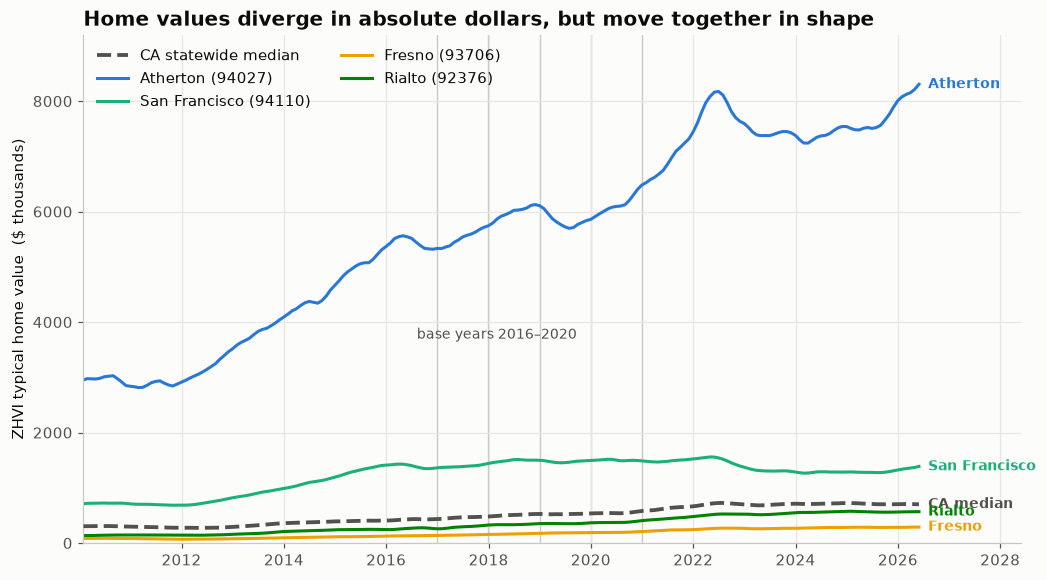

In [18]:
months = [c for c in zhvi.columns if c[:4].isdigit() and c >= "2010-01"]
dates = pd.to_datetime(months)

# Identity is carried by a legend AND by direct labels at the right-hand end, so the series are
# never distinguished by colour alone.
picks = {"94027": "Atherton", "94110": "San Francisco", "93706": "Fresno", "92376": "Rialto"}

fig, ax = plt.subplots(figsize=(11, 6))
statewide = zhvi[months].median()
ax.plot(dates, statewide / 1000, color=GRAY, lw=2.5, ls="--", label="CA statewide median", zorder=5)
ax.annotate("CA median", (dates[-1], statewide.iloc[-1] / 1000), xytext=(6, 0),
            textcoords="offset points", color=GRAY, fontweight="bold", va="center", fontsize=9)

for (z, name), c in zip(picks.items(), CATEGORICAL):
    s = zhvi.loc[z, months]
    ax.plot(dates, s / 1000, color=c, lw=2, label=f"{name} ({z})")
    ax.annotate(name, (dates[-1], s.iloc[-1] / 1000), xytext=(6, 0), textcoords="offset points",
                color=c, fontweight="bold", va="center", fontsize=9)

for y in BASE_YEARS:
    ax.axvline(pd.Timestamp(f"{y}-12-31"), color="#c9c8c3", lw=0.9, zorder=0)
ax.annotate("base years 2016–2020", (pd.Timestamp("2018-03-01"), 3700), color=GRAY, fontsize=9,
            ha="center")

ax.set_title("Home values diverge in absolute dollars, but move together in shape")
ax.set_ylabel("ZHVI typical home value  ($ thousands)")
ax.set_xlim(dates[0], dates[-1] + pd.Timedelta(days=730))
ax.set_ylim(0, 9200)
ax.legend(loc="upper left", ncol=2)
save(fig, "figB_home_value_trends")
plt.show()

**Result — the levels diverge exactly as expected, but the *turning points are shared*.**

Atherton sits an order of magnitude above Fresno ($6.5M vs ~$230k), yet all four ZIP codes and the
statewide median bend at the *same moments*: the 2012 trough, the steady 2015–2019 climb, the
near-vertical 2020–2022 surge, and the 2023 plateau. **Local level is idiosyncratic; local timing is
not.**

**Insight — two things follow.**

1. **A statewide, year-level shock moves every ZIP code at once.** So `base_year` is a first-order
   variable, not a bookkeeping column, and rows sharing a base year are **not independent** — they
   share a common macro shock. Any train/test split that ignores this will overstate its own accuracy.
2. **It justifies predicting growth rather than price level.** The price *level* of a ZIP code is
   essentially its geography, and geography is not something a model needs to "learn." Growth is the
   part that actually has to be explained.

## Figure C — The mortgage rate over the study period

**Why this factor.** The mortgage rate sets the cost of borrowing, and borrowing is how almost every
home is bought. It is the one genuinely macroeconomic variable in the feature set, so I want to see
what values it actually took across the base years — and, just as importantly, what it did during the
**outcome windows** the model is trying to explain.

**What I expect.** I expect a fairly narrow band across 2016–2020 (rates were historically low and
stable), followed by the well-known spike. If that is true, then the mortgage rate has a problem as a
feature: with only five base years it contributes only **five distinct values** to the whole panel,
identical for every ZIP code within a year. I expect this figure to *disqualify* it as a serious
predictor, and I want to see that limitation before any model can hide it behind a
feature-importance bar.

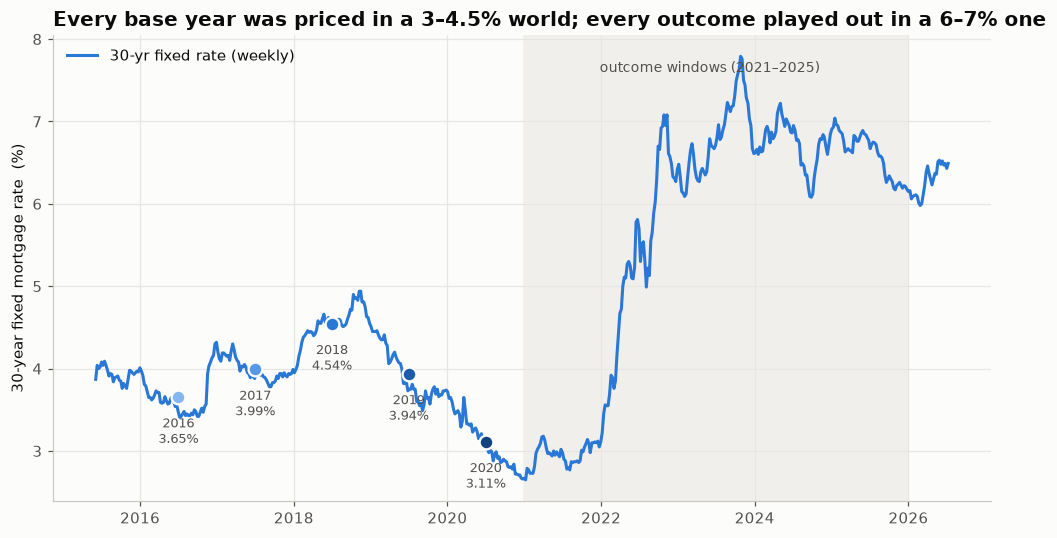

mortgage rate across the five base years: 3.11% – 4.54%   (only 5 distinct values)


In [19]:
fred_plot = fred[fred["observation_date"] >= "2015-06-01"]
annual = df.groupby("base_year")["mortgage_rate"].first()

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(fred_plot["observation_date"], fred_plot["MORTGAGE30US"], color=BLUE, lw=2,
        label="30-yr fixed rate (weekly)")

for (y, r), c in zip(annual.items(), YEAR_COLORS):
    ax.plot(pd.Timestamp(f"{y}-07-01"), r, "o", ms=9, color=c, mec="#fcfcfb", mew=1.5, zorder=5)
    ax.annotate(f"{y}\n{r:.2f}%", (pd.Timestamp(f"{y}-07-01"), r), xytext=(0, -30),
                textcoords="offset points", ha="center", fontsize=8.5, color=GRAY)

ax.axvspan(pd.Timestamp("2021-01-01"), pd.Timestamp("2025-12-31"), color="#f0efec", zorder=0)
ax.annotate("outcome windows (2021–2025)", (pd.Timestamp("2023-06-01"), 7.6), ha="center",
            fontsize=9, color=GRAY)
ax.set_title("Every base year was priced in a 3–4.5% world; every outcome played out in a 6–7% one")
ax.set_ylabel("30-year fixed mortgage rate  (%)")
ax.legend(loc="upper left")
save(fig, "figC_mortgage_rate")
plt.show()

print(f"mortgage rate across the five base years: "
      f"{annual.min():.2f}% – {annual.max():.2f}%   (only {annual.nunique()} distinct values)")

**Result — confirmed, and worse than expected.** The five base-year values span just **3.11%–4.54%**,
while the outcomes they are supposed to explain unfolded through a spike above **7%** (shaded).

**Insight — the mortgage rate must be treated as a control, not a predictor, and I will hold this
against it later.**

1. **It is a national, year-level constant.** Every ZIP code in a given year receives the identical
   value, so it is structurally incapable of explaining why one ZIP outgrew *another* — only why one
   year differed from another. With five base years it is effectively **five data points wearing
   7,487 costumes.**
2. **It is perfectly confounded with `base_year`.** Any correlation it shows with the target is
   really a base-year effect in disguise (Figure F will show exactly this).
3. **The training range does not cover the present.** Rates today sit far outside 3.11–4.54%, so any
   attempt to predict the future with this feature is extrapolation beyond anything the data has
   seen — and tree-based models cannot extrapolate at all; they clamp to the edge of their training
   range.

## Figure D — The distribution of the target

**Why this factor.** Before choosing any model, I need to know the shape of what I am predicting.
Skew, spread and tail behaviour determine whether a transformation is warranted, which error metric
is appropriate, and how much damage extreme rows can do. I plot the target pooled, and then split by
base year.

**What I expect.** Growth rates are ratios bounded below by −100% but unbounded above, so the
textbook expectation is a **clear right skew**, and the conventional response is a log transform. I
expect to confirm that and apply one. I also expect the base years to look broadly similar — a ZIP's
five-year growth shouldn't depend *that* much on whether the clock started in 2016 or 2020.

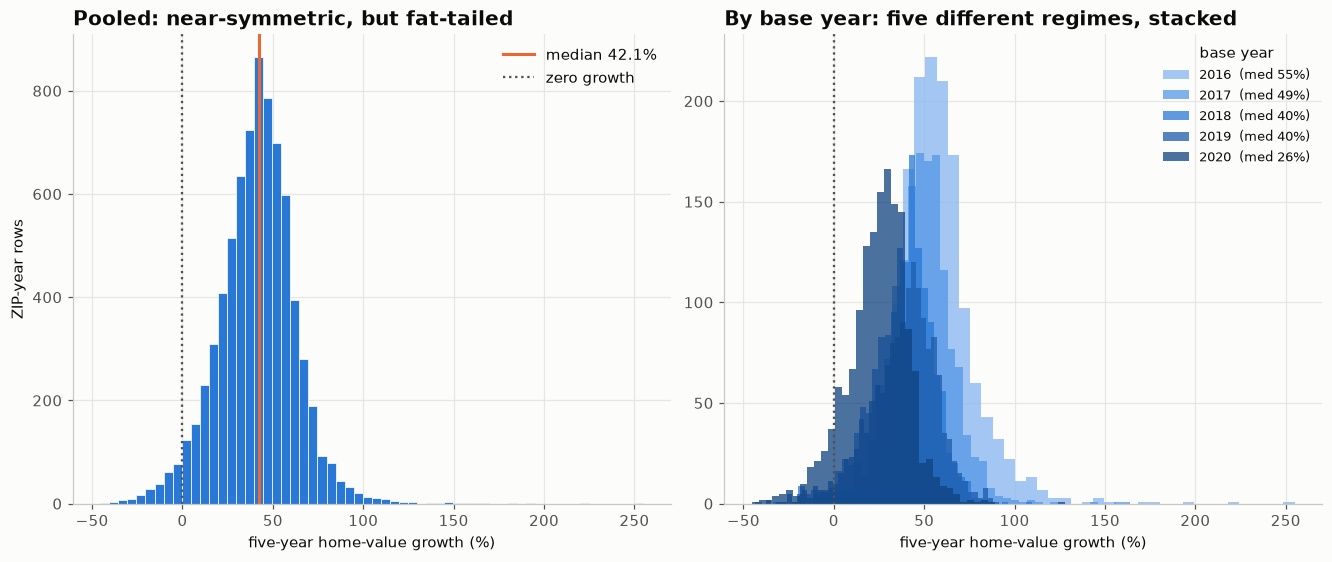

pooled   mean 41.2%   median 42.1%   sd 21.6   skew 0.31   excess kurtosis 3.80
rows with negative growth: 256 (3.4%)

           mean  median   std    min    max
base_year                                  
2016      57.90   55.30 21.00 -23.60 254.90
2017      48.30   48.80 17.70 -33.40 163.60
2018      37.90   40.10 17.30 -43.40 109.80
2019      38.20   40.40 19.00 -37.40  91.10
2020      24.30   26.20 17.30 -45.50 127.80


In [20]:
t = df["future_5yr_growth_pct"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")

ax = axes[0]
ax.hist(t, bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(t.median(), color=ACCENT, lw=2, label=f"median {t.median():.1f}%")
ax.axvline(0, color=GRAY, lw=1.5, ls=":", label="zero growth")
ax.set_title("Pooled: near-symmetric, but fat-tailed")
ax.set_xlabel("five-year home-value growth (%)")
ax.set_ylabel("ZIP-year rows")
ax.legend()

ax = axes[1]
for (y, g), c in zip(df.groupby("base_year"), YEAR_COLORS):
    ax.hist(g["future_5yr_growth_pct"], bins=45, color=c, alpha=0.75, histtype="stepfilled",
            label=f"{y}  (med {g['future_5yr_growth_pct'].median():.0f}%)")
ax.axvline(0, color=GRAY, lw=1.5, ls=":")
ax.set_title("By base year: five different regimes, stacked")
ax.set_xlabel("five-year home-value growth (%)")
ax.legend(title="base year", fontsize=8.5)

save(fig, "figD_target_distribution")
plt.show()

print(f"pooled   mean {t.mean():.1f}%   median {t.median():.1f}%   sd {t.std():.1f}"
      f"   skew {t.skew():.2f}   excess kurtosis {t.kurt():.2f}")
print(f"rows with negative growth: {(t < 0).sum()} ({(t < 0).mean() * 100:.1f}%)")
print()
print(df.groupby("base_year")["future_5yr_growth_pct"]
        .agg(["mean", "median", "std", "min", "max"]).round(1).to_string())

**Result — both expectations were wrong, and the second one badly.**

**The target is not meaningfully skewed.** Skew is **+0.31**, and the mean (41.2%) is essentially the
median (42.1%). Pooled, the distribution is close to symmetric. **A log transform would buy
essentially nothing, so I am not applying one** — and I want to be explicit that I am declining it on
the evidence rather than performing it out of habit. What the distribution *does* have is **fat tails
(excess kurtosis 3.81)**, and the correct response to fat tails is *robustness to extreme rows*, not
a transformation. That is precisely what the outlier **flag** from §2.8 is designed to support.

**The base years are not similar at all — this is the real finding.** Median growth falls
**monotonically: 55% → 49% → 40% → 40% → 26%** from base year 2016 to 2020. A ZIP code bought in 2016
and held five years roughly doubled the gain of the same ZIP bought in 2020.

**Insight.** That gradient is the pandemic housing boom being **progressively consumed**. Each later
base year starts the clock with more of the surge already behind it. Three consequences:

- **`base_year` is a first-order variable**, confirming Figure B.
- **Every one of the five outcome windows contains the boom**, so any model built here learns "what
  predicted growth *during a boom*" — a real limit on how far its conclusions travel.
- **The rows are not independent**: overlapping outcome windows mean the 2016 and 2017 rows for one
  ZIP share four years of price history. A naive random train/test split would leak and report a
  flattering, meaningless accuracy.

## Figure E — Household income vs. home value

**Why these factors.** Income is the most obvious candidate explanation for housing outcomes, and it
is the first thing anyone would reach for. Plotting it against home value tests whether the dataset
behaves sensibly at all — a basic sanity check on the merge between Zillow and Census — and it sets
up the far more important question of whether income also predicts **growth**.

**What I expect.** A strong positive relationship with home *value*: rich areas have expensive
houses. That much is near-certain. The interesting question is whether that same relationship carries
over to *growth* — I expect it to be positive but weaker, on the theory that prosperous areas keep
appreciating.

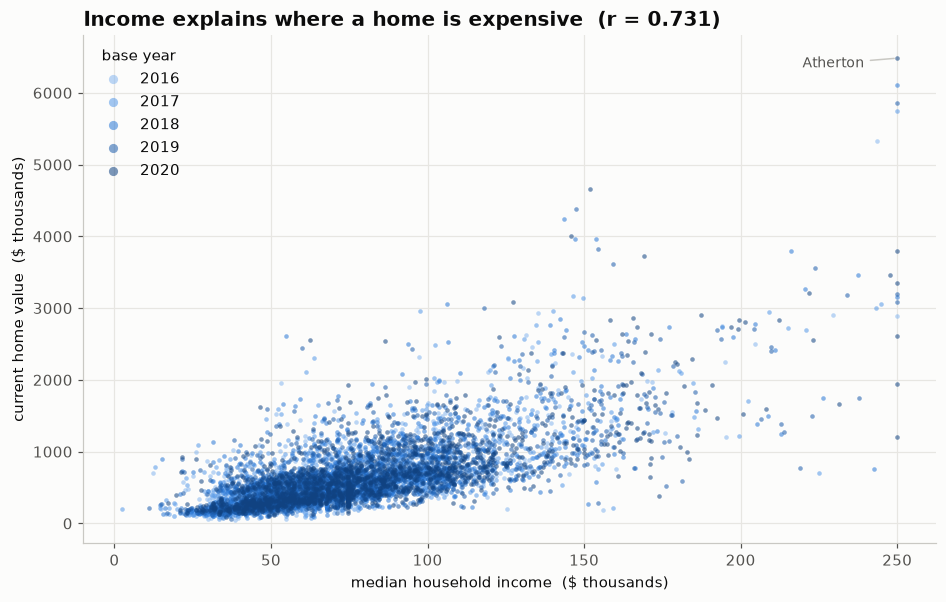

corr(income, home VALUE)   r = +0.731
corr(income, future GROWTH) r = -0.136


In [21]:
fig, ax = plt.subplots(figsize=(10, 6))
for (y, g), c in zip(df.groupby("base_year"), YEAR_COLORS):
    ax.scatter(g["median_household_income"] / 1000, g["current_home_value"] / 1000,
               s=9, alpha=0.55, color=c, label=str(y), linewidths=0)

r_value = df["median_household_income"].corr(df["current_home_value"])
r_growth = df["median_household_income"].corr(df["future_5yr_growth_pct"])

ax.set_title(f"Income explains where a home is expensive  (r = {r_value:.3f})")
ax.set_xlabel("median household income  ($ thousands)")
ax.set_ylabel("current home value  ($ thousands)")
ax.legend(title="base year", markerscale=2)
ax.annotate("Atherton", (df.loc[df.current_home_value.idxmax(), "median_household_income"] / 1000,
                         df["current_home_value"].max() / 1000),
            xytext=(-62, -6), textcoords="offset points", fontsize=9, color=GRAY,
            arrowprops=dict(arrowstyle="-", color="#c9c8c3"))
save(fig, "figE_income_vs_value")
plt.show()

print(f"corr(income, home VALUE)   r = {r_value:+.3f}")
print(f"corr(income, future GROWTH) r = {r_growth:+.3f}")

**Result — the first expectation holds emphatically (r = +0.73). The second one is simply false
(r = −0.14, and it is *negative*).**

**Insight — this gap is the most important thing in the whole exploration.** Income tells you where
homes are **expensive**. It tells you almost nothing about where they will **appreciate** — and what
little it says points the *wrong way*. **Prosperity is a level effect, not a growth effect.** Any
model that leans on income to predict growth is leaning on the wrong variable, and the most intuitive
feature in the dataset turns out to be one of the weakest.

Two secondary observations, both consequential:

- **The relationship fans out.** Below ~$100k income the value band is tight; above ~$150k it
  explodes vertically — two ZIP codes with identical $200k incomes can differ by millions. That
  heteroskedasticity, plus the clear right skew in both variables, means **income and home value are
  good candidates for a log transform on the *feature* side** (unlike the target, which as Figure D
  showed does not need one).
- The base-year colours are thoroughly intermixed, which tells us the income–value relationship is
  stable across years even though growth is not.

If income does not predict growth, what does? The negative sign is the clue — and it motivates the
next figure.

## Figure F — The affordability-constraint hypothesis

**Why these factors.** Figure E produced a puzzle: richer areas grow *slightly slower*. The natural
explanation is **affordability**. A market whose prices have already run far beyond what local
incomes and rents can support has little room left to rise; a market that is cheap *relative to local
earnings* has room to catch up. Testing that requires a variable that captures price **relative to**
local means — which is exactly what `price_to_income_ratio` and `price_to_rent_ratio` are.

This is the central hypothesis of the analysis, so it gets the most careful test.

**What I expect.** A **negative** relationship between the price-to-income ratio and future growth.

**And I expect one specific objection**, so I test for it in the same figure. A pooled correlation
could be an artifact of `base_year`: Figure D showed that base years differ hugely in growth, and if
expensive years also happened to be slow years, a spurious negative correlation would appear even
with no real effect. The hypothesis is only credible if the relationship **also holds *inside* each
individual base year**. The right-hand panel is that test — and it is the one I actually care about.

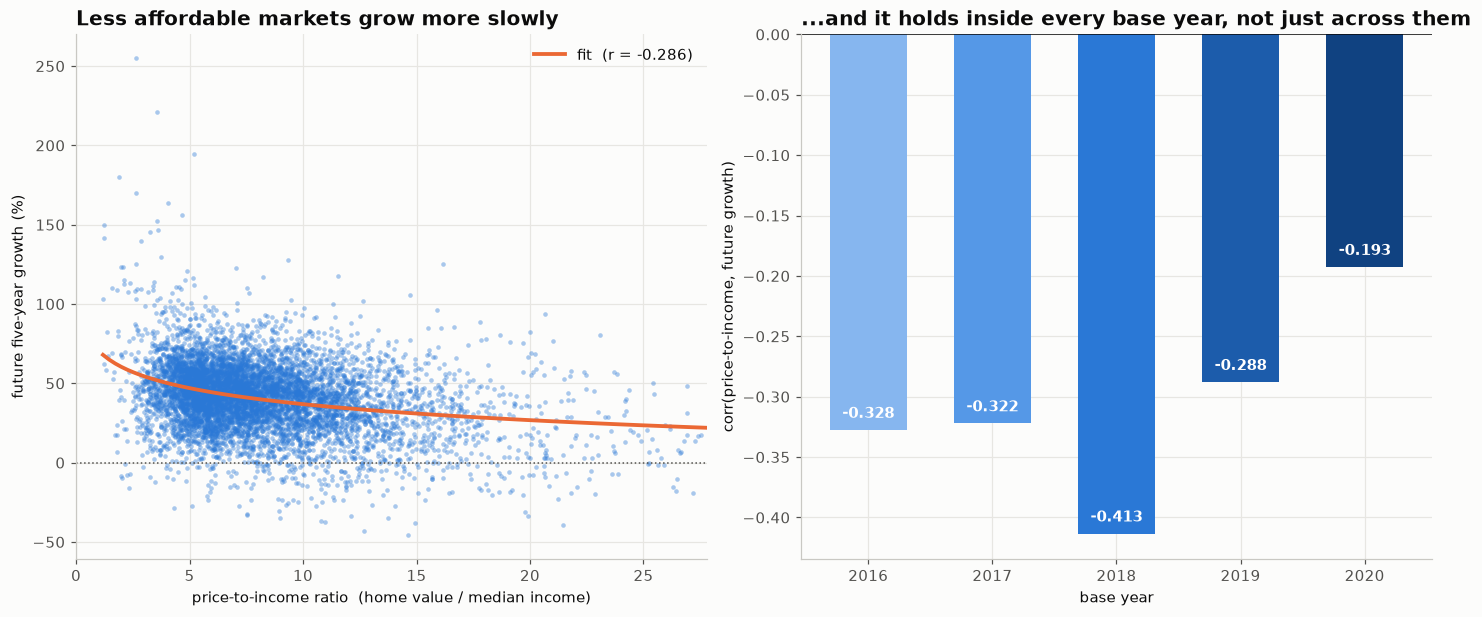

pooled  corr(price_to_income, growth) = -0.286
pooled  corr(price_to_rent,   growth) = -0.305

for comparison, the ratio's own ingredients:
  income alone      r = -0.136
  home value alone  r = -0.228


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")

ax = axes[0]
ax.scatter(df["price_to_income_ratio"], df["future_5yr_growth_pct"],
           s=9, alpha=0.4, color=BLUE, linewidths=0)
r_all = df["price_to_income_ratio"].corr(df["future_5yr_growth_pct"])
# Trend fitted on the LOG of the ratio, because the ratio is heavily right-skewed.
x = df["price_to_income_ratio"].clip(lower=0.1)
b, a = np.polyfit(np.log(x), df["future_5yr_growth_pct"], 1)
xs = np.linspace(x.min(), x.quantile(0.995), 100)
ax.plot(xs, a + b * np.log(xs), color=ACCENT, lw=2.5, label=f"fit  (r = {r_all:.3f})")
ax.axhline(0, color=GRAY, lw=1, ls=":")
ax.set_xlim(0, df["price_to_income_ratio"].quantile(0.995))
ax.set_title("Less affordable markets grow more slowly")
ax.set_xlabel("price-to-income ratio  (home value / median income)")
ax.set_ylabel("future five-year growth (%)")
ax.legend()

# The critical control: does the effect survive INSIDE each base year?
ax = axes[1]
within = df.groupby("base_year").apply(
    lambda g: g["price_to_income_ratio"].corr(g["future_5yr_growth_pct"]), include_groups=False)
bars = ax.bar([str(y) for y in within.index], within.values, color=YEAR_COLORS, width=0.62)
for rect, v in zip(bars, within.values):
    ax.annotate(f"{v:.3f}", (rect.get_x() + rect.get_width() / 2, v), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=9.5, color="white",
                fontweight="bold")
ax.axhline(0, color="#0b0b0b", lw=1)
ax.set_title("...and it holds inside every base year, not just across them")
ax.set_ylabel("corr(price-to-income, future growth)")
ax.set_xlabel("base year")
save(fig, "figF_affordability_hypothesis")
plt.show()

print(f"pooled  corr(price_to_income, growth) = {r_all:+.3f}")
print(f"pooled  corr(price_to_rent,   growth) = "
      f"{df['price_to_rent_ratio'].corr(df['future_5yr_growth_pct']):+.3f}")
print(f"\nfor comparison, the ratio's own ingredients:")
print(f"  income alone      r = {df['median_household_income'].corr(df['future_5yr_growth_pct']):+.3f}")
print(f"  home value alone  r = {df['current_home_value'].corr(df['future_5yr_growth_pct']):+.3f}")

**Result — the hypothesis is supported, and it survives the objection.**

`price_to_rent_ratio` (**r = −0.305**) and `price_to_income_ratio` (**r = −0.286**) are the two
strongest correlates of future growth in the entire dataset, both negative and in the predicted
direction. **A market already priced beyond what local incomes can carry has less room left to run.**

**The right-hand panel is what makes this credible.** The effect appears **inside every single base
year**, from −0.19 (2020) to −0.41 (2018). It is a genuine cross-sectional relationship between ZIP
codes, not an artifact of the base-year regimes that Figure D exposed. Had those bars been near zero,
the pooled correlation would have been worthless — this is the check that earns the finding.

**Insight — and a note on feature engineering.** The derived ratio **beats both of its own
ingredients**: income alone manages r = −0.14 and home value alone r = −0.23, but their *ratio*
reaches −0.29. Neither raw column carries the signal on its own; the **relationship between them**
does. That is the strongest argument in this dataset for constructing ratio features rather than
feeding in raw columns, and it directly resolves the puzzle Figure E raised.

**Stated honestly:** r ≈ −0.3 is a **moderate** effect, explaining roughly 9% of the variance on its
own. It is a real signal, not a law, and it should not be oversold.

## Figure G — Outliers in context

**Why this plot.** §2.8 flagged 236 growth outliers and 450 value outliers and deleted none. That was
a consequential decision, so it deserves visual evidence rather than an assertion. I plot every row
by home value (log scale, because value spans two orders of magnitude) against growth, with the
flagged rows highlighted.

**What I expect.** If the flagged rows are *errors*, they should look like nonsense — isolated,
implausible, clustered in some corner. If they are *real markets*, they should look like coherent
extremes: expensive coastal ZIP codes on one side, and unusually large gains or losses spread across
the whole price range. I expect the latter, which would justify keeping them.

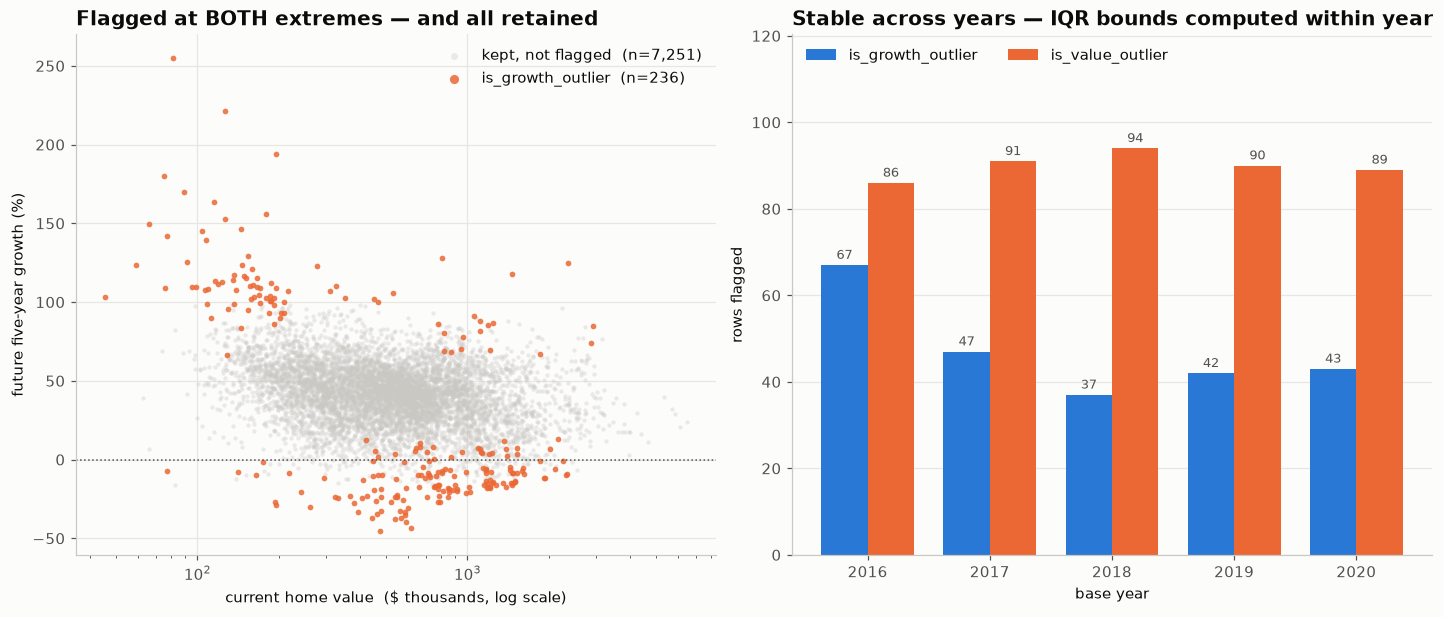

mean home value, value-outlier rows: $2,023,213
mean home value, all other rows:     $542,721


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")

ax = axes[0]
normal, out = df[df.is_growth_outlier == 0], df[df.is_growth_outlier == 1]
ax.scatter(normal["current_home_value"] / 1000, normal["future_5yr_growth_pct"], s=8, alpha=0.35,
           color="#c9c8c3", linewidths=0, label=f"kept, not flagged  (n={len(normal):,})")
ax.scatter(out["current_home_value"] / 1000, out["future_5yr_growth_pct"], s=14, alpha=0.85,
           color=ACCENT, linewidths=0, label=f"is_growth_outlier  (n={len(out):,})")
ax.set_xscale("log")
ax.axhline(0, color=GRAY, lw=1, ls=":")
ax.set_xlabel("current home value  ($ thousands, log scale)")
ax.set_ylabel("future five-year growth (%)")
ax.set_title("Flagged at BOTH extremes — and all retained")
ax.legend(markerscale=1.6, loc="upper right")

ax = axes[1]
counts = df.groupby("base_year")[["is_growth_outlier", "is_value_outlier"]].sum()
w, xs = 0.38, np.arange(len(counts))
b1 = ax.bar(xs - w / 2, counts["is_growth_outlier"], w, color=BLUE, label="is_growth_outlier")
b2 = ax.bar(xs + w / 2, counts["is_value_outlier"], w, color=ACCENT, label="is_value_outlier")
for bars in (b1, b2):
    ax.bar_label(bars, fontsize=8.5, color=GRAY, padding=2)
ax.set_xticks(xs, [str(y) for y in counts.index])
ax.set_xlabel("base year")
ax.set_ylabel("rows flagged")
ax.set_title("Stable across years — IQR bounds computed within year")
ax.set_ylim(0, counts.values.max() * 1.28)
ax.legend(loc="upper left", ncol=2)
ax.grid(axis="x", visible=False)
save(fig, "figG_outliers_flagged")
plt.show()

print(f"mean home value, value-outlier rows: "
      f"${df.loc[df.is_value_outlier == 1, 'current_home_value'].mean():,.0f}")
print(f"mean home value, all other rows:     "
      f"${df.loc[df.is_value_outlier == 0, 'current_home_value'].mean():,.0f}")

**Result — they are real markets, exactly as expected, and the case for keeping them is now visual.**

The growth outliers (orange) sit at **both** extremes — large gains *and* large losses — and they are
spread across the **entire price range** rather than clustering among expensive ZIP codes. They are
unusual **outcomes**, not bad **data**. Meanwhile the value outliers average **$2.02M** against
**$543k** for everyone else: that is not a corrupted-record signature, that is the California coast.

**Insight.** Deleting these rows would have removed the most expensive markets in the state — which
are *precisely* the observations the affordability hypothesis in Figure F is about. The theory says
markets priced far beyond local incomes should grow slowly; the least affordable markets in
California are the outliers. **Truncating the top of the price distribution would have quietly
deleted the strongest test of the central hypothesis.**

The right-hand panel confirms the within-year IQR bounds behave sensibly: flag counts are stable
across base years (37–67 growth, 86–94 value) rather than dumping an entire year into the outlier
bucket, which is what a single pooled bound would have done.

## Figure H — Home value and growth by base year

**Why these factors.** Figure D found that the base years differ in growth. Box plots put the *whole
distribution* of both `current_home_value` and `future_5yr_growth_pct` side by side per year —
median, spread, and tails at once — which a histogram overlay makes harder to compare precisely.

**What I expect.** For home value: a strong right skew in every year, with a long upper tail of
luxury markets (this is what the IQR flag was reacting to in §2.8). For growth: a steady decline in
the median across base years, confirming Figure D — and I want to see whether the *spread* narrows
too, or whether only the centre moves.

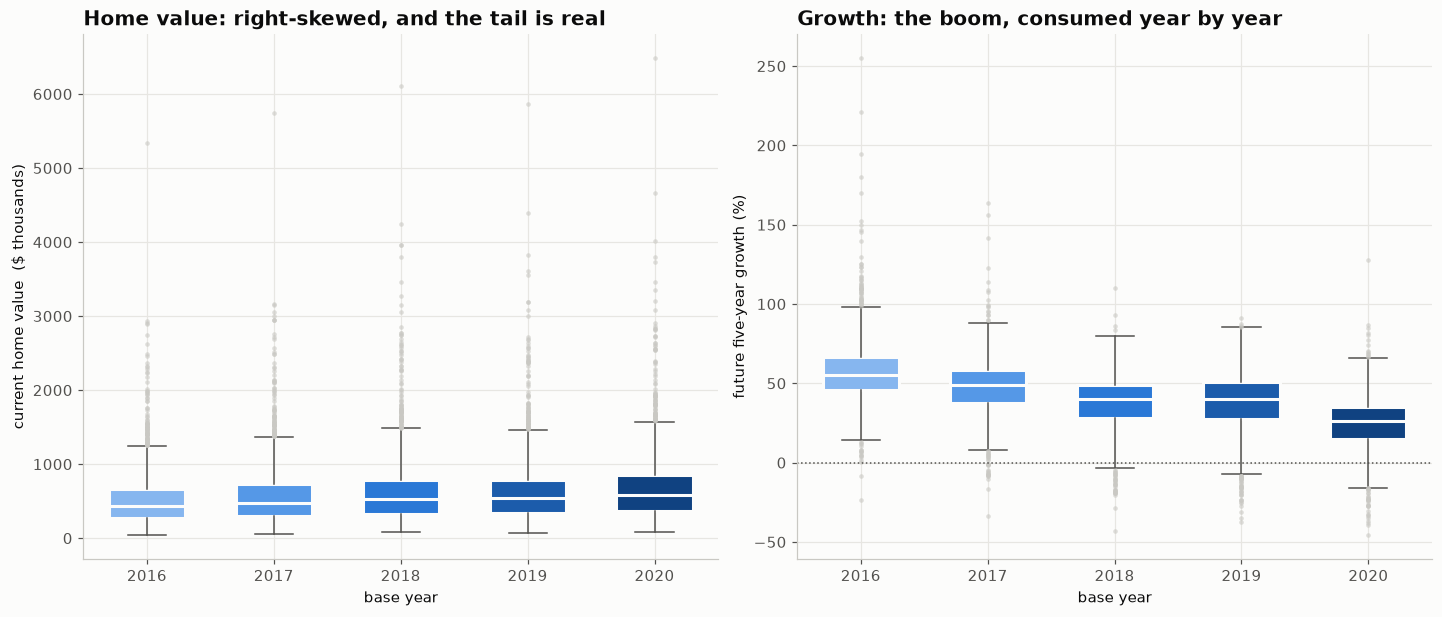

          current_home_value            future_5yr_growth_pct      
                      median        std                median   std
base_year                                                          
2016              435,432.80 411,688.00                 55.30 21.00
2017              480,807.10 453,571.80                 48.80 17.70
2018              528,901.10 518,815.40                 40.10 17.30
2019              539,256.60 495,197.20                 40.40 19.00
2020              580,468.20 524,084.20                 26.20 17.30


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
years = sorted(df["base_year"].unique())

def styled_box(ax, data, ylabel, title):
    bp = ax.boxplot(data, tick_labels=[str(y) for y in years], patch_artist=True, widths=0.6,
                    flierprops=dict(marker="o", ms=3, mfc="#c9c8c3", mec="none", alpha=0.6),
                    medianprops=dict(color="#fcfcfb", lw=2),
                    whiskerprops=dict(color=GRAY), capprops=dict(color=GRAY))
    for patch, c in zip(bp["boxes"], YEAR_COLORS):
        patch.set_facecolor(c)
        patch.set_edgecolor("#fcfcfb")     # surface gap between adjacent fills
        patch.set_linewidth(2)
    ax.set_xlabel("base year")
    ax.set_ylabel(ylabel)
    ax.set_title(title)

styled_box(axes[0], [df.loc[df.base_year == y, "current_home_value"] / 1000 for y in years],
           "current home value  ($ thousands)", "Home value: right-skewed, and the tail is real")
styled_box(axes[1], [df.loc[df.base_year == y, "future_5yr_growth_pct"] for y in years],
           "future five-year growth (%)", "Growth: the boom, consumed year by year")
axes[1].axhline(0, color=GRAY, lw=1, ls=":")
save(fig, "figH_boxplots_by_year")
plt.show()

print(df.groupby("base_year")[["current_home_value", "future_5yr_growth_pct"]]
        .agg(["median", "std"]).round(1).to_string())

**Result — both expectations confirmed, and the two panels tell opposite stories.**

**Left — home value is heavily right-skewed in every single year.** The box (the middle 50%) sits low
and a long tail of flier points stretches far above it. Those fliers are the Athertons and Malibus of
§2.8 — real markets, not errors. The median California ZIP roughly rose from ~$430k (2016) to ~$660k
(2020), and the *spread widened with it*: expensive markets pulled away in absolute dollars.

**Right — growth falls monotonically, 55% → 26%,** confirming Figure D with the full distribution
rather than just the median. Notably the **spread does not collapse** — the boxes stay a similar
height while sliding downward. So later base years are not "less variable," they are uniformly
*shifted down*. The whole market moved together, which is the same story Figure B told with lines.

**Insight.** This is the **most important caveat in the entire analysis**: every one of the five
outcome windows contains the pandemic housing boom, and each successive base year captures less of
it. Any model trained here learns "what predicted growth *during a boom*." That constrains how far
these conclusions can be pushed toward a different rate environment, and no amount of
cross-validation repairs it — it is a property of the data, not of the model.

## Figure I — Correlation heatmap

**Why this plot.** The figures so far tested variables one or two at a time. The heatmap shows every
pairwise relationship at once, and answers two questions that individual scatter plots cannot:
(1) which features correlate with the **target**, and (2) which features correlate with **each
other** — because the second one determines whether a linear model's coefficients can be trusted at
all.

**What I expect.** Based on Figures E and F, I expect the affordability ratios to lead the target
column and no single feature to be dominant. On collinearity I have a strong prior: income, rent,
education and home value are all proxies for the same underlying thing — *how affluent this ZIP code
is* — so I expect a tight, highly correlated block among them. If so, ordinary least squares will be
unreliable here, and a regularized model will be necessary rather than optional.

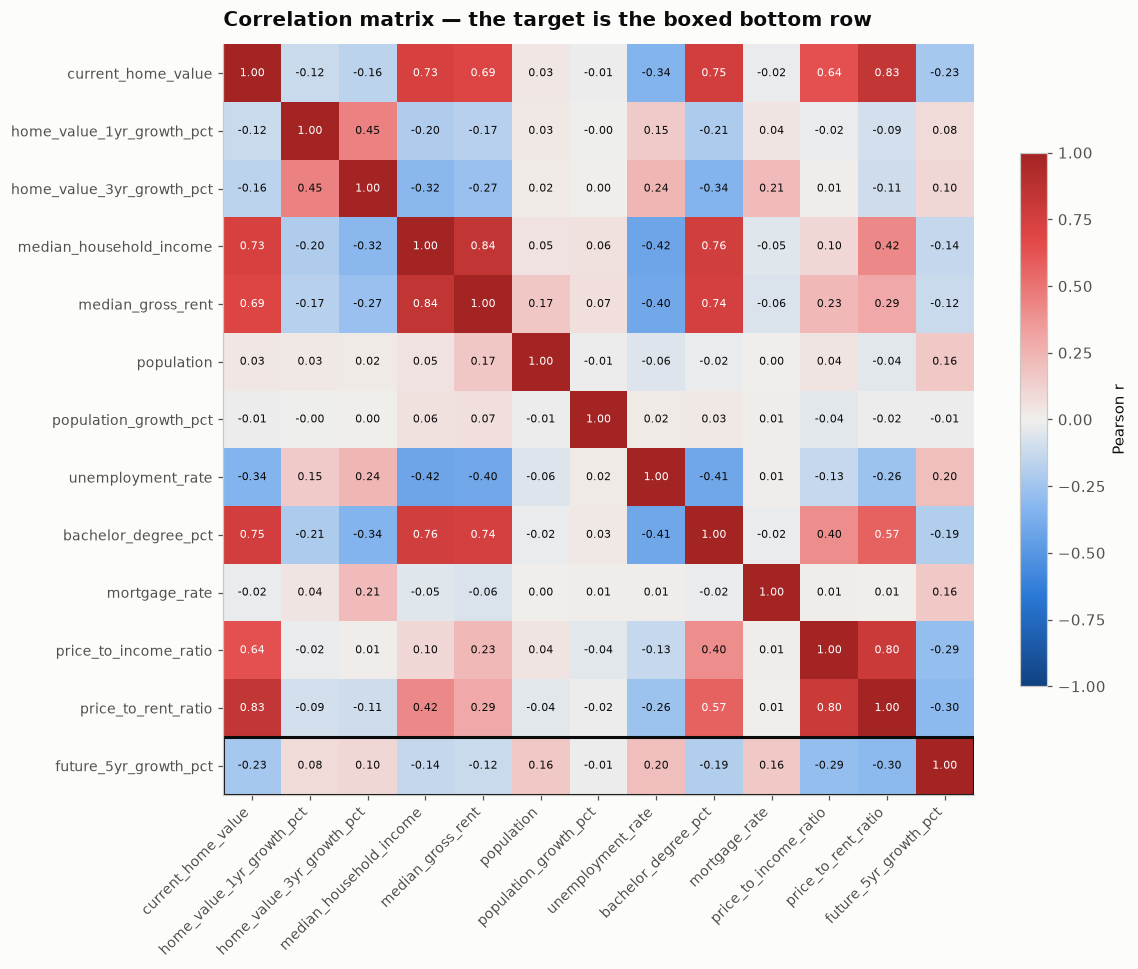

correlation with future_5yr_growth_pct, strongest first:
price_to_rent_ratio         -0.30
price_to_income_ratio       -0.29
current_home_value          -0.23
unemployment_rate            0.20
bachelor_degree_pct         -0.19
mortgage_rate                0.16
population                   0.16
median_household_income     -0.14
median_gross_rent           -0.12
home_value_3yr_growth_pct    0.10
home_value_1yr_growth_pct    0.08
population_growth_pct       -0.01


In [25]:
corr = df[CORE + ["future_5yr_growth_pct"]].corr()
labels = CORE + ["future_5yr_growth_pct"]

fig, ax = plt.subplots(figsize=(11, 9))
# Diverging map, GRAY at zero: "no correlation" must read as "nothing", which a rainbow cannot do.
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(labels)), labels, fontsize=9)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.55 else "#0b0b0b")
# The target is the row that matters; mark it rather than making the reader hunt for it.
ax.add_patch(plt.Rectangle((-0.5, len(labels) - 1.5), len(labels), 1, fill=False,
                           edgecolor="#0b0b0b", lw=2))
ax.set_title("Correlation matrix — the target is the boxed bottom row", pad=12)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Pearson r")
save(fig, "figI_correlation_heatmap")
plt.show()

print("correlation with future_5yr_growth_pct, strongest first:")
print(corr["future_5yr_growth_pct"].drop("future_5yr_growth_pct")
          .sort_values(key=abs, ascending=False).round(3).to_string())

**Result — both expectations confirmed, and the collinearity is worse than I anticipated.**

**1. No feature is individually strong.** The best correlate is `price_to_rent_ratio` at **−0.305**;
nothing reaches 0.35. There is **no single dominant predictor** — five-year growth is genuinely
multivariate. This sets a realistic expectation for any model built on this data: a moderate R² is
the honest ceiling, and a very high one would be evidence of leakage (most likely
`future_5yr_home_value` accidentally left in the feature matrix), not of success.

**2. The affluence features are severely collinear.** This is the block that matters:

| Pair | r |
|---|---|
| `median_household_income` ↔ `median_gross_rent` | **+0.84** |
| `bachelor_degree_pct` ↔ `median_household_income` | **+0.76** |
| `current_home_value` ↔ `bachelor_degree_pct` | **+0.75** |
| `current_home_value` ↔ `median_household_income` | **+0.73** |

**Insight — this dictates the choice of model.** Income, rent, education and home value are four
measurements of one latent quantity: how affluent a ZIP code is. Under ordinary least squares that is
destructive — with predictors this correlated, the coefficients become unstable and **their signs can
flip on a resampling**. The predictions might still be fine, but the *explanation* becomes worthless,
and explanation is half the point of this analysis. **A regularized regression such as Ridge, whose
L2 penalty distributes weight across correlated predictors instead of arbitrarily crowning one of
them, is therefore required rather than merely preferred.** That conclusion is a response to the
+0.84, not a stylistic preference.

Two further notes. `unemployment_rate` correlates **positively** with growth (**+0.199**) — which
sounds backwards until you recognise it as the affordability story again: high unemployment marks
cheap inland markets that had the most room to catch up. It is not a claim that joblessness causes
appreciation. And `mortgage_rate`'s **+0.158** is exactly the artifact Figure C predicted: five
values, one per base year, so it is a `base_year` effect in disguise.

## Figure J — Ranking every feature against the target

**Why this plot.** The heatmap contains the answer but buries it in a 13×13 grid. This is simply the
target column, sorted, so that the ranking — and, critically, the **sign** of each relationship —
can be read directly.

**What I expect.** The affordability ratios at the top, income weak, mortgage rate mid-table but
meaningless. The one I am least sure about is **momentum** (`home_value_1yr_growth_pct` and
`home_value_3yr_growth_pct`). The single most intuitive belief in real estate is that rising markets
keep rising, so I expect momentum to be a solid positive predictor — and if it isn't, that is a
genuinely surprising result worth reporting.

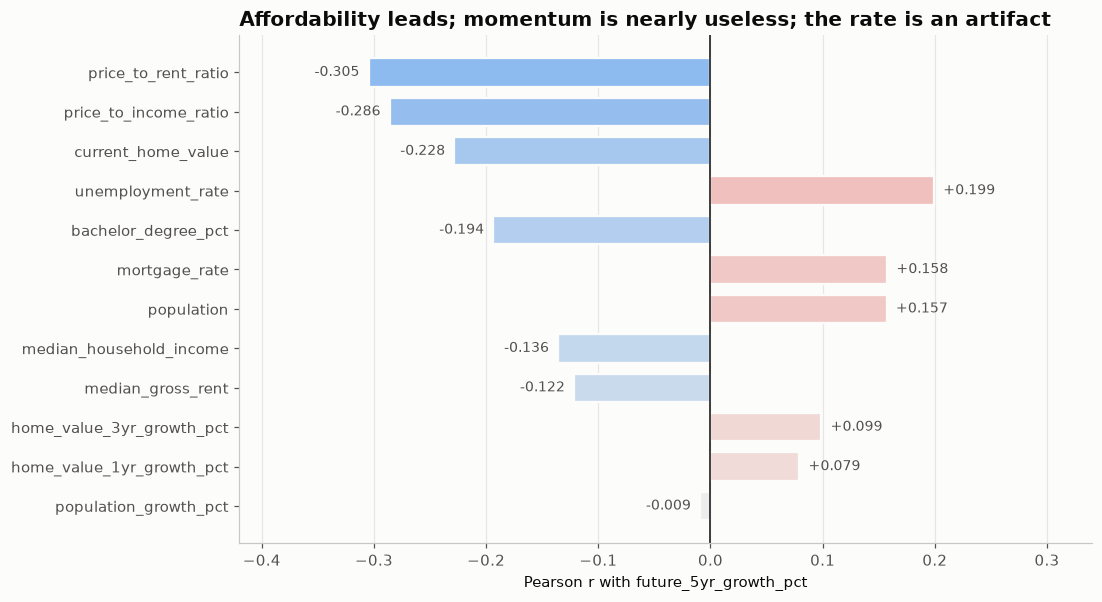

In [26]:
target_corr = (corr["future_5yr_growth_pct"].drop("future_5yr_growth_pct").sort_values(key=abs))

fig, ax = plt.subplots(figsize=(10, 6))
# Diverging colour, because the SIGN is the message: does this feature push growth up or down?
colors = [DIVERGING(0.5 + v / 2) for v in target_corr.values]
ax.barh(target_corr.index, target_corr.values, color=colors, height=0.72,
        edgecolor="#fcfcfb", linewidth=1.5)
for i, v in enumerate(target_corr.values):
    ax.annotate(f"{v:+.3f}", (v, i), xytext=(6 if v > 0 else -6, 0), textcoords="offset points",
                va="center", ha="left" if v > 0 else "right", fontsize=9, color=GRAY)
ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_xlim(-0.42, 0.34)
ax.set_xlabel("Pearson r with future_5yr_growth_pct")
ax.set_title("Affordability leads; momentum is nearly useless; the rate is an artifact")
ax.grid(axis="y", visible=False)
save(fig, "figJ_target_correlations")
plt.show()

**Result — the ranking overturns the one expectation I held most confidently.**

**Momentum fails.** `home_value_1yr_growth_pct` (**+0.079**) and `home_value_3yr_growth_pct`
(**+0.099**) are close to worthless. The most intuitive idea in real estate — *"it has been going up,
so it will keep going up"* — has **almost no predictive power at a five-year horizon.** Recent price
momentum simply does not persist that far out. (It may well persist over one year; that is a
different question from the one this dataset asks.) This is the finding I would have bet against, and
it is the one most worth reporting.

**What does work is affordability.** The top three are `price_to_rent_ratio` (−0.305),
`price_to_income_ratio` (−0.286) and `current_home_value` (−0.228) — all **negative**, all saying the
same thing: **cheap markets grew, expensive markets lagged.** Five-year growth in California was a
catch-up story, not a rich-get-richer story.

**What is fake is `mortgage_rate` (+0.158).** It looks respectable and mid-table, and it is an
illusion — five values, one per base year, exactly as Figure C warned.

**And one true null: `population_growth_pct` (−0.009).** People moving *in* does not predict prices
going *up*. But `population` **level** is +0.157 — so urban **scale** carries signal while urban
**change** does not.

---
# 4. Insights, and how they guide the modeling that follows

Written after seeing the numbers, not before.

### 4.1 The features that look promising

**Affordability is the signal.** `price_to_rent_ratio` (−0.305) and `price_to_income_ratio` (−0.286)
lead every ranking, and — decisively — the effect **survives within every individual base year**
(Figure F), so it is a real cross-sectional relationship and not a macro coincidence. Both are
**engineered** features that outperform their own raw ingredients, which is the clearest argument in
this dataset for building ratios rather than feeding in columns.

`current_home_value` (−0.228) and `unemployment_rate` (+0.199) restate the same story: cheap,
economically slack, inland markets had the most room to catch up, and they did.

### 4.2 The features that disappoint — and why that is worth knowing

- **Momentum is nearly useless** at this horizon (r ≈ +0.08 to +0.10). The most intuitive feature in
  real estate does not survive contact with the data.
- **Income predicts price level, not price growth** (+0.73 vs −0.14).
- **`population_growth_pct` is a true null** (−0.009).
- **`mortgage_rate` is a base-year effect in disguise** and must be treated as a market-cycle control,
  never sold as a predictor on a feature-importance chart.

### 4.3 Collinearity — and why a regularized model is required

Income ↔ rent is **+0.84**; education ↔ income **+0.76**; home value ↔ education **+0.75**. These
four columns are measuring one latent quantity: *how affluent this ZIP code is*.

Ordinary least squares on a block like this produces unstable coefficients whose signs can flip under
resampling — the predictions may be acceptable while the *explanation* is worthless. **A regularized
regression (Ridge, L2) distributes weight across correlated predictors instead of arbitrarily
selecting one, and is therefore the appropriate choice here.** This is an empirical response to the
+0.84, not a stylistic one.

### 4.4 Distribution — no target transformation, but robustness matters

Skew is **+0.31** and mean ≈ median, so **the target does not need a log transform** and none is
applied. The real distributional issue is **fat tails (excess kurtosis 3.81)**, which calls for
robustness to extreme rows rather than a transformation. The **features**, by contrast, are strongly
right-skewed (`current_home_value`, `median_household_income`, `population`) — a log transform on the
*feature* side is worth testing.

### 4.5 What the outlier decision implies

236 growth outliers (3.2%) and 450 value outliers (6.0%) are **flagged and retained**. Because they
are legitimate extreme markets rather than errors, the modeling stage should fit **with** them by
default, refit **without** them as a robustness check, and **report the difference** rather than
quietly choosing whichever looks better. Models tolerant of fat tails — regularized linear models on
scaled features, and tree ensembles — are preferable.

### 4.6 The leakage trap that must not be sprung

Median growth falls **55% → 26%** across base years (Figures D and H), and the five outcome windows
**overlap**: the 2016 and 2017 rows for a given ZIP code share four years of price history.

> **7,487 rows are not 7,487 independent observations.** A random train/test split would leak badly
> and produce a flattering, meaningless accuracy score. Any split must be made **by base year** — for
> example, train on earlier base years and test on a later one — so that the model is evaluated on a
> market regime it has not already seen.

### 4.7 A realistic expectation

No feature exceeds |r| = 0.31, and the target is genuinely multivariate. A **moderate** R² is the
honest ceiling for a five-year-ahead prediction. **An R² near 0.9 should be read as evidence of
leakage — most likely `future_5yr_home_value` left in the feature matrix — not as success.**

---
# 5. Saving the cleaned dataset

In [27]:
OUT = ROOT / "data" / "processed" / "ca_zip_housing_panel_clean.csv"
OUT.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(OUT, index=False)

print(f"wrote {OUT.relative_to(ROOT)}")
print(f"  {len(df):,} rows x {df.shape[1]} columns")
print(f"  {len(list(FIGURES.glob('*.png')))} figures in figures/")
print("\nrows per base year:")
print(df["base_year"].value_counts().sort_index().to_string())

wrote data/processed/ca_zip_housing_panel_clean.csv
  7,487 rows x 28 columns
  20 figures in figures/

rows per base year:
base_year
2016    1452
2017    1496
2018    1500
2019    1511
2020    1528


In [28]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
base_year,"7,487.00","2,018.02",1.41,"2,016.00","2,017.00","2,018.00","2,019.00","2,020.00"
current_home_value,"7,487.00","631,704.45","486,374.06","45,530.06","319,162.78","510,901.92","767,292.83","6,483,301.32"
home_value_1yr_growth_pct,"7,487.00",7.66,6.29,-19.07,4.02,7.25,10.28,48.56
home_value_3yr_growth_pct,"7,487.00",25.55,12.12,-21.59,17.49,23.86,31.45,107.77
median_household_income,"7,487.00","74,564.08","33,702.19","2,499.00","50,678.50","67,759.00","91,522.00","250,001.00"
median_gross_rent,"7,487.00","1,453.41",506.45,342.00,"1,081.00","1,382.00","1,745.00","3,501.00"
population,"7,487.00","26,015.51","22,291.13",2.00,"4,882.00","23,464.00","40,044.00","111,165.00"
population_growth_pct,"7,487.00",4.53,24.32,-93.10,-1.16,2.91,7.56,646.81
unemployment_rate,"7,487.00",7.51,5.18,0.00,4.60,6.47,9.22,100.00
bachelor_degree_pct,"7,487.00",32.51,19.82,0.00,16.67,28.48,45.73,95.37


---
# 6. Summary

**Dataset.** 7,487 California ZIP-year records across five base years (2016–2020), with 12 core
features and a measured five-year home-price growth outcome. Sources: Zillow (home values, rents,
listings), US Census ACS 5-Year (demographics) and FRED (mortgage rate).

### Cleaning steps and the reasoning behind each

| Step | Action | Reason |
|---|---|---|
| Census sentinels | `-666666666` → `NaN` (verified: 0 survive) | A valid-looking number that silently destroys every statistic |
| Duplicate ZIP-years | Assert none; fail loudly (0 found) | A duplicate means a join bug — hiding it would hide the bug |
| Impossible values | Out-of-range → `NaN`, never → 0 | `NaN` says "unknown"; 0 asserts a falsehood |
| Missing target / denominator | **Drop** (0 rows) | **Never impute what you are predicting** |
| Missing Census features | **Median-impute within base year** (172 income, 409 rent, ~35 others) | A 2016 median is not a 2020 median; the median resists skew |
| Derived ratios | Recompute **after** imputation | Keeps each ratio consistent with its own ingredients |
| Rent index (78% missing) | **Keep, flag, never impute** | Missingness is severe *and* non-random — imputing would manufacture a correlation |
| Listings, pre-2018 | **Leave null, never impute** | **Structurally absent, not missing** — the series does not exist |
| Outliers | **Flag 236 + 450, delete 0** | Atherton at $6.5M is not an error; deleting it would delete the signal |

**Result: zero missing values in the target, in `current_home_value`, and across all 12 core
features.** Every remaining null is a documented decision, not an oversight.

### The four findings that matter

1. **Affordability constrains growth.** `price_to_rent` (−0.305) and `price_to_income` (−0.286) are
   the strongest correlates, and the effect **holds inside every base year**. Cheap markets caught
   up; expensive ones lagged. Five-year growth in California was a catch-up story.
2. **The intuitive features fail.** Income predicts price *level* (+0.73) but not *growth* (−0.14),
   and **price momentum is nearly useless** at a five-year horizon (r ≈ +0.08). The most obvious
   place to look was the wrong place.
3. **The affluence features are collinear** (income ↔ rent = **+0.84**), so a **regularized model is
   required** if the coefficients are to mean anything.
4. **The rows are not independent.** The five outcome windows overlap and all contain the pandemic
   boom (median growth falls 55% → 26%), so any evaluation split must be made **by base year, never
   randomly.**